<a href="https://colab.research.google.com/github/Shredder2010/adaptive-therapy-model/blob/main/adaptive_therapy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import numpy as np

PARAMS = {
    "rS": 0.30, "rR": 0.15, "K": 10_000, "d": 0.60,
    "S0": 7_425, "R0": 75, "dt": 0.1, "days": 150,
}
PROGRESSION_MULTIPLE = 1.20


def simulate(
    strategy,
    *,
    rS=PARAMS["rS"],
    rR=PARAMS["rR"],
    K=PARAMS["K"],
    d=PARAMS["d"],
    S0=PARAMS["S0"],
    R0=PARAMS["R0"],
    days=PARAMS["days"],
    dt=PARAMS["dt"],
    pause_fraction=0.5,
):
    """Simulate sensitive and resistant cells under a treatment strategy."""
    if strategy not in {"continuous", "adaptive"}:
        raise ValueError("strategy must be 'continuous' or 'adaptive'")

    S, R = float(S0), float(R0)
    N0 = S + R
    drug = True

    times = [0.0]
    S_values = [S]
    R_values = [R]
    drug_history = [drug]

    for i in range(int(days / dt)):
        total = S + R

        if strategy == "adaptive":
            if drug and total <= pause_fraction * N0:
                drug = False
            elif not drug and total >= N0:
                drug = True

        free_space = 1 - total / K
        D = 1 if drug else 0

        # Calculate both changes from the old S and R values.
        dS = dt * (rS * S * free_space - d * D * S)
        dR = dt * (rR * R * free_space)

        S += dS
        R += dR

        times.append((i + 1) * dt)
        S_values.append(S)
        R_values.append(R)
        drug_history.append(drug)

    times = np.array(times)
    S_values = np.array(S_values)
    R_values = np.array(R_values)
    totals = S_values + R_values
    drug_history = np.array(drug_history, dtype=bool)

    threshold = PROGRESSION_MULTIPLE * N0
    reached = np.flatnonzero(totals > threshold)

    if len(reached):
        progression_day = float(times[reached[0]])
        drug_days = float(drug_history[1:reached[0] + 1].sum() * dt)
    else:
        progression_day = float("nan")
        drug_days = float(drug_history[1:].sum() * dt)

    return {
        "times": times,
        "S": S_values,
        "R": R_values,
        "total": totals,
        "drug_on": drug_history,
        "progression_day": progression_day,
        "drug_days": drug_days,
        "threshold": threshold,
    }


continuous = simulate("continuous")
adaptive = simulate("adaptive")

for name, result in [("Continuous", continuous), ("Adaptive", adaptive)]:
    print(
        f"{name}: progression at {result['progression_day']:.1f} days; "
        f"{result['drug_days']:.1f} drug days"
    )

Continuous: progression at 49.2 days; 49.2 drug days
Adaptive: progression at 76.7 days; 35.5 drug days


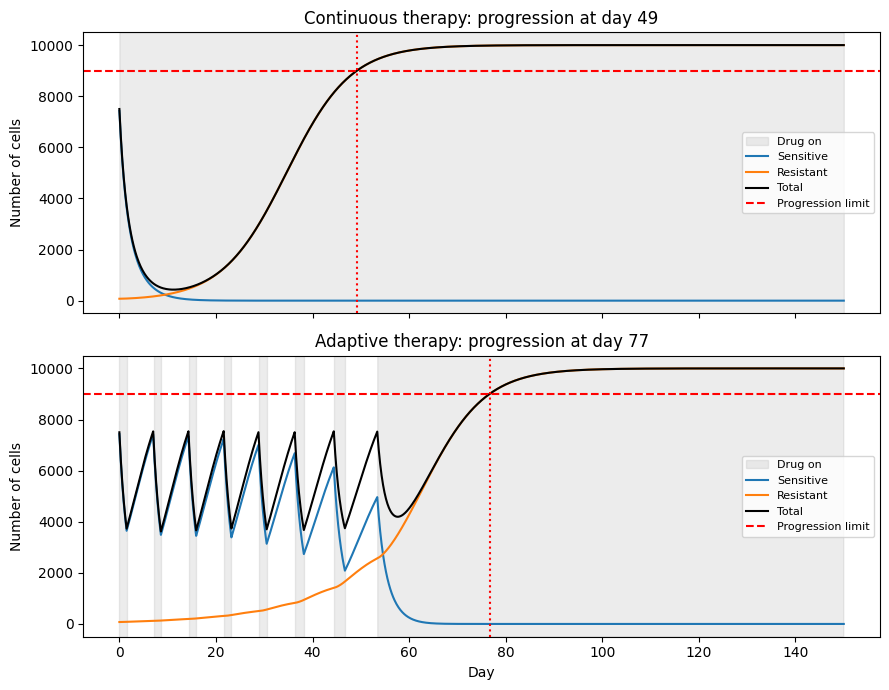

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

for ax, result, title in [(axes[0], continuous, "Continuous therapy"),
                          (axes[1], adaptive, "Adaptive therapy")]:
    t = result["times"]

    # Shade the times the drug is on
    ax.fill_between(t, 0, 1, where=result["drug_on"],
                    transform=ax.get_xaxis_transform(),
                    color="gray", alpha=0.15, label="Drug on")

    # Cell populations
    ax.plot(t, result["S"], label="Sensitive")
    ax.plot(t, result["R"], label="Resistant")
    ax.plot(t, result["total"], color="black", label="Total")

    # Progression limit and the day it was crossed
    ax.axhline(result["threshold"], linestyle="--", color="red", label="Progression limit")
    ax.axvline(result["progression_day"], linestyle=":", color="red")

    ax.set_title(f"{title}: progression at day {result['progression_day']:.0f}")
    ax.set_ylabel("Number of cells")
    ax.legend(loc="center right", fontsize=8)

axes[1].set_xlabel("Day")
plt.tight_layout()
plt.savefig("main_figure.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
plt.savefig("main_figure.png", dpi=200, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>